# Lab 6: EuroSAT Land-Use Classification with PyTorch — Designing and Training a CNN

**Name:** Qiwen Bian  **Date:** 2026-10-13

This notebook designs, implements and trains convolutional neural networks in PyTorch to classify
EuroSAT RGB satellite patches (Sentinel-2, 64×64 px) into the 10 land use / land cover categories,
starting from the course starter notebook (instr. Xiaojiang Li) and run on a Colab **T4 GPU**
runtime. The strategy is "baseline, then upgrade one thing at a time": a small baseline CNN sets the
reference point, then architecture (BatchNorm, residual blocks, global average pooling), transfer
learning (ImageNet-pretrained ResNet-18) and regularization/augmentation are added one variable at
a time, each judged on a held-out validation split. Only the final winner touches the test set,
exactly once.

**Workflow:** (1) prepare the modules and check the GPU, (2) download EuroSAT (27,000 images, 10
classes), make a stratified 70/15/15 train/val/test split, estimate channel mean/std on the training
split only, build the DataLoaders and inspect the data, (3) train a small baseline CNN as the
reference, (4) train a ResNet-style CNN designed from scratch, (5) fine-tune a pretrained ResNet-18,
(6) run controlled ablations (augmentation, weight decay, label smoothing), (7) evaluate the best
model on the test set — confusion matrix, per-class accuracy, error analysis | outputs: experiment
log table, `best_model.pt`, `confusion_matrix.png`, misclassified-example grid.

## Step 1: Prepare the modules

In [ ]:
import random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms, models
from torch.utils.data import Subset, DataLoader
import matplotlib.pyplot as plt

# Colab ships with torch / torchvision / sklearn / pandas — nothing to pip-install.

# fixed seed: the split, model init and shuffles are the same on every rerun
seed = 42
random.seed(seed); np.random.seed(seed)
torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = True     # fixed 64x64 inputs -> let cuDNN pick fast kernels

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("device:", device)

PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
GPU available: True
GPU: Tesla T4
device: cuda


## Step 2: Download EuroSAT and build the data pipeline

EuroSAT (Helber et al., 2019) holds 27,000 Sentinel-2 RGB patches (64×64 px) in 10 land-use classes.
The split is stratified 70/15/15 with a fixed seed — val drives every model-selection decision
below, test stays locked until Step 7. Channel mean/std for normalization are estimated **on the
training split only**, so no statistics leak in from unseen data.

In [ ]:
# EuroSAT RGB, auto-downloaded from Zenodo (~90 MB) into ./data/eurosat/2750
# (if Zenodo is flaky: mkdir -p data/eurosat && wget https://zenodo.org/record/7711810/files/EuroSAT.zip -P data/eurosat && unzip -q data/eurosat/EuroSAT.zip -d data/eurosat)
raw = datasets.EuroSAT(root="./data", download=True)
class_names = raw.classes
print("images:", len(raw), "| classes:", len(class_names))
print(class_names)

100%|██████████| 94.3M/94.3M [00:00<00:00, 98.5MB/s]


images: 27000 | classes: 10
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [ ]:
from sklearn.model_selection import train_test_split

targets = np.array(raw.targets)     # class index of every image (folder order = class_names)
idx = np.arange(len(targets))

# stratified 70/15/15: every split keeps the same class proportions
train_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=targets, random_state=seed)
val_idx,  test_idx = train_test_split(tmp_idx, test_size=0.50, stratify=targets[tmp_idx], random_state=seed)

print(f"train {len(train_idx)} / val {len(val_idx)} / test {len(test_idx)}")

train 18900 / val 4050 / test 4050


In [ ]:
# channel mean/std estimated on the TRAIN split only (ToTensor already scales pixels to [0,1])
stats_ds = datasets.EuroSAT(root="./data", download=False, transform=transforms.ToTensor())
stats_loader = DataLoader(Subset(stats_ds, train_idx), batch_size=512, num_workers=2)

mean = torch.zeros(3); std = torch.zeros(3); n = 0
for imgs, _ in stats_loader:
    b = imgs.size(0)
    mean += imgs.mean(dim=[0, 2, 3]) * b
    std  += imgs.std(dim=[0, 2, 3])  * b
    n += b
mean, std = mean / n, std / n
print("mean =", mean.tolist(), "\nstd  =", std.tolist())

mean = [0.34390074014663696, 0.37995412945747375, 0.4075494110584259] 
std  = [0.20224739611148834, 0.1365811973810196, 0.11531855911016464]


In [ ]:
eval_tf = transforms.Compose([            # val/test stay pure -> deterministic evaluation
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
plain_tf = transforms.Compose([           # Step 6 swaps this for augmented versions, train only
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

def make_loaders(train_tf, batch_size=64):
    """Rebuild the three loaders — reused in Step 6 whenever the augmentation changes."""
    train_set = Subset(datasets.EuroSAT(root="./data", download=False, transform=train_tf), train_idx)
    val_set   = Subset(datasets.EuroSAT(root="./data", download=False, transform=eval_tf),  val_idx)
    test_set  = Subset(datasets.EuroSAT(root="./data", download=False, transform=eval_tf),  test_idx)
    return (DataLoader(train_set, batch_size=batch_size, shuffle=True,  num_workers=2, pin_memory=True),
            DataLoader(val_set,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True),
            DataLoader(test_set,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True))

train_loader, val_loader, test_loader = make_loaders(plain_tf)

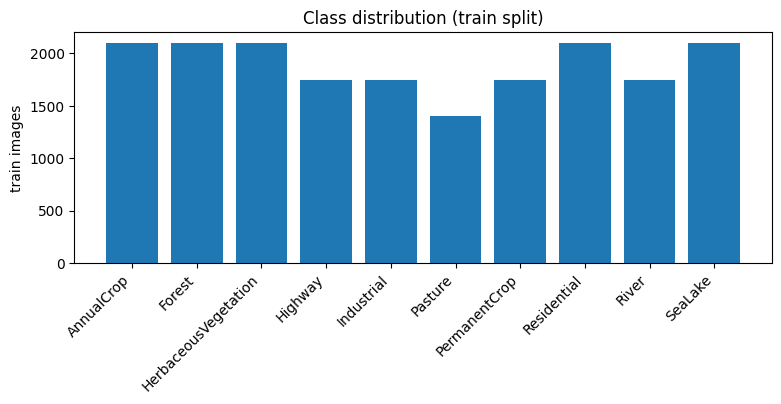

AnnualCrop             2100
Forest                 2100
HerbaceousVegetation   2100
Highway                1750
Industrial             1750
Pasture                1400
PermanentCrop          1750
Residential            2100
River                  1750
SeaLake                2100


In [ ]:
# class distribution — mildly imbalanced (2,000-3,000 images per class)
counts = np.bincount(targets[train_idx])
plt.figure(figsize=(9, 3))
plt.bar(class_names, counts)
plt.xticks(rotation=45, ha="right"); plt.ylabel("train images")
plt.title("Class distribution (train split)"); plt.show()
for c, k in zip(class_names, counts): print(f"{c:22s} {k}")

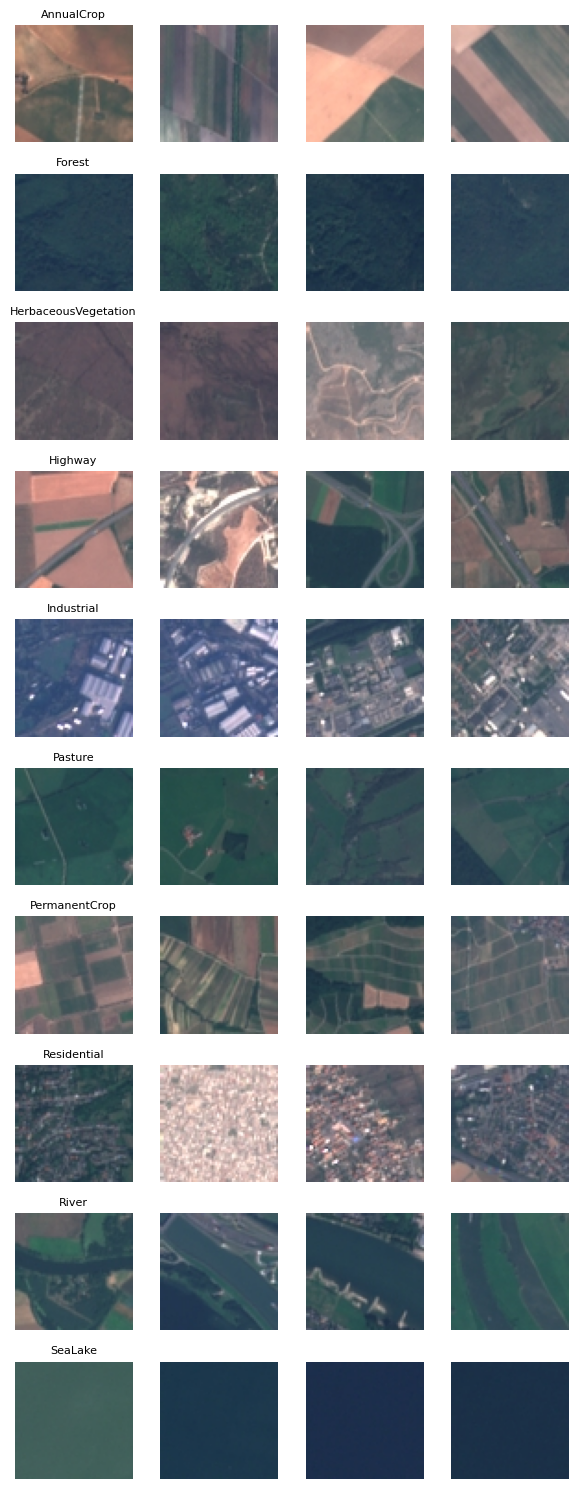

In [ ]:
# 10 classes x 4 samples straight from the raw (un-normalized) dataset
rng = np.random.default_rng(seed)
fig, axes = plt.subplots(10, 4, figsize=(6, 15))
for c in range(10):
    ids = rng.choice(np.where(targets == c)[0], size=4, replace=False)
    for j, i in enumerate(ids):
        img, _ = raw[int(i)]
        axes[c, j].imshow(img); axes[c, j].axis("off")
        if j == 0: axes[c, j].set_title(class_names[c], fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# sanity checks before any training
xb, yb = next(iter(train_loader))
print("images:", xb.shape, "| labels:", yb.shape, "| label range:", int(yb.min()), "-", int(yb.max()))
print("normalized pixel range:", round(float(xb.min()), 3), "to", round(float(xb.max()), 3))

images: torch.Size([64, 3, 64, 64]) | labels: torch.Size([64]) | label range: 0 - 9
normalized pixel range: -1.691 to 5.138


## Step 3: Training framework and the baseline CNN

One `train_model` routine serves every experiment: AdamW + cosine LR, best-val-accuracy
checkpointing, and a history dict logged into `RESULTS` — the auto-built experiment log the
Discussion leans on. The baseline CNN is deliberately simple (3 conv + max-pool blocks, one hidden
FC layer), so every later gain can be attributed to a specific change rather than tuning noise.

In [ ]:
RESULTS = {}   # experiment name -> history
MODELS   = {}   # experiment name -> trained model (best-val checkpoint restored)

@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        logits = model(x)
        loss_sum += loss_fn(logits, y).item() * y.size(0)
        correct  += (logits.argmax(1) == y).sum().item()
        n += y.size(0)
    return loss_sum / n, correct / n

def train_model(model, name, epochs=20, lr=1e-3, weight_decay=0.0, label_smoothing=0.0,
                train_ld=None, val_ld=None, param_groups=None):
    """Train one model, roll back to the best val-acc checkpoint, log the history."""
    train_ld, val_ld = train_ld or train_loader, val_ld or val_loader
    loss_fn = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    opt = torch.optim.AdamW(param_groups if param_groups is not None else model.parameters(),
                            lr=lr, weight_decay=weight_decay)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state = 0.0, None
    for ep in range(1, epochs + 1):
        model.train()
        loss_sum, correct, n = 0.0, 0, 0
        for x, y in train_ld:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            logits = model(x)
            loss = loss_fn(logits, y)
            loss.backward()
            opt.step()
            loss_sum += loss.item() * y.size(0)
            correct  += (logits.argmax(1) == y).sum().item()
            n += y.size(0)
        sch.step()
        tr_loss, tr_acc = loss_sum / n, correct / n
        va_loss, va_acc = evaluate(model, val_ld, loss_fn)
        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss);   history["val_acc"].append(va_acc)
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"[{name}] epoch {ep:02d}/{epochs}  train {tr_acc:.4f}  val {va_acc:.4f}  (best {best_acc:.4f})")

    model.load_state_dict(best_state)
    history["best_val_acc"] = best_acc
    RESULTS[name], MODELS[name] = history, model
    return history

def plot_history(name):
    h = RESULTS[name]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
    ax1.plot(h["train_loss"], label="train"); ax1.plot(h["val_loss"], label="val")
    ax1.set_title(f"{name} — loss"); ax1.set_xlabel("epoch"); ax1.legend()
    ax2.plot(h["train_acc"], label="train"); ax2.plot(h["val_acc"], label="val")
    ax2.set_title(f"{name} — accuracy"); ax2.set_xlabel("epoch"); ax2.legend()
    plt.show()

In [ ]:
class BaselineCNN(nn.Module):
    """3 conv + max-pool blocks and one hidden FC layer — the reference point."""
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 64 -> 32
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32 -> 16
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 16 -> 8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(seed)
baseline = BaselineCNN().to(device)
print("parameters:", sum(p.numel() for p in baseline.parameters()))

parameters: 2193226


[baseline_cnn] epoch 01/20  train 0.6466  val 0.7667  (best 0.7667)
[baseline_cnn] epoch 02/20  train 0.7915  val 0.8143  (best 0.8143)
[baseline_cnn] epoch 03/20  train 0.8440  val 0.8437  (best 0.8437)
[baseline_cnn] epoch 04/20  train 0.8748  val 0.8741  (best 0.8741)
[baseline_cnn] epoch 05/20  train 0.9012  val 0.8790  (best 0.8790)
[baseline_cnn] epoch 06/20  train 0.9214  val 0.8886  (best 0.8886)
[baseline_cnn] epoch 07/20  train 0.9356  val 0.9022  (best 0.9022)
[baseline_cnn] epoch 08/20  train 0.9542  val 0.8958  (best 0.9022)
[baseline_cnn] epoch 09/20  train 0.9628  val 0.8899  (best 0.9022)
[baseline_cnn] epoch 10/20  train 0.9747  val 0.9109  (best 0.9109)
[baseline_cnn] epoch 11/20  train 0.9771  val 0.9205  (best 0.9205)
[baseline_cnn] epoch 12/20  train 0.9859  val 0.9173  (best 0.9205)
[baseline_cnn] epoch 13/20  train 0.9903  val 0.9175  (best 0.9205)
[baseline_cnn] epoch 14/20  train 0.9931  val 0.9215  (best 0.9215)
[baseline_cnn] epoch 15/20  train 0.9944  val 0.

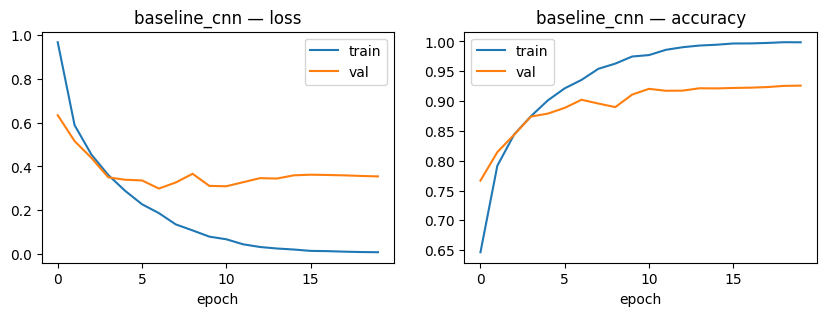

In [ ]:
train_model(baseline, "baseline_cnn", epochs=20, lr=1e-3)
plot_history("baseline_cnn")

## Step 4: Architecture upgrade — a ResNet-style CNN designed from scratch

Three upgrades over the baseline, each targeting a known failure mode: **BatchNorm** keeps
activations centred so deeper stacks train stably, **residual shortcuts** give gradients a clean
identity path so depth stops hurting, and **global average pooling** replaces the giant flatten —
far fewer parameters, less overfitting. Four stages downsample 64→8 px while widening 64→512
channels; training runs longer (30 epochs) because the deeper net keeps improving past the
baseline's plateau.

In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(cout)
        self.shortcut = (nn.Identity() if (stride == 1 and cin == cout) else
                         nn.Sequential(nn.Conv2d(cin, cout, 1, stride=stride, bias=False),
                                       nn.BatchNorm2d(cout)))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))     # identity path carries signal & gradient

class EuroResNet(nn.Module):
    """ResNet-style CNN for 64x64 inputs: stem -> 4 stages (64->512 ch) -> GAP -> head."""
    def __init__(self, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(64), nn.ReLU())
        self.stage1 = nn.Sequential(ResidualBlock(64, 64),  ResidualBlock(64, 64))            # 64x64
        self.stage2 = nn.Sequential(ResidualBlock(64, 128, stride=2),  ResidualBlock(128, 128))  # 32
        self.stage3 = nn.Sequential(ResidualBlock(128, 256, stride=2), ResidualBlock(256, 256))  # 16
        self.stage4 = nn.Sequential(ResidualBlock(256, 512, stride=2), ResidualBlock(512, 512))  # 8
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(0.2), nn.Linear(512, num_classes))
    def forward(self, x):
        x = self.stem(x)
        x = self.stage4(self.stage3(self.stage2(self.stage1(x))))
        return self.head(x)

torch.manual_seed(seed)
euro_resnet = EuroResNet().to(device)
print("parameters:", sum(p.numel() for p in euro_resnet.parameters()))

parameters: 11173962


[euro_resnet] epoch 01/30  train 0.6315  val 0.6983  (best 0.6983)
[euro_resnet] epoch 02/30  train 0.7586  val 0.6170  (best 0.6983)
[euro_resnet] epoch 03/30  train 0.8046  val 0.8474  (best 0.8474)
[euro_resnet] epoch 04/30  train 0.8477  val 0.8348  (best 0.8474)
[euro_resnet] epoch 05/30  train 0.8644  val 0.8484  (best 0.8484)
[euro_resnet] epoch 06/30  train 0.8888  val 0.8622  (best 0.8622)
[euro_resnet] epoch 07/30  train 0.8997  val 0.8968  (best 0.8968)
[euro_resnet] epoch 08/30  train 0.9107  val 0.8983  (best 0.8983)
[euro_resnet] epoch 09/30  train 0.9268  val 0.9099  (best 0.9099)
[euro_resnet] epoch 10/30  train 0.9320  val 0.9111  (best 0.9111)
[euro_resnet] epoch 11/30  train 0.9394  val 0.9338  (best 0.9338)
[euro_resnet] epoch 12/30  train 0.9504  val 0.9417  (best 0.9417)
[euro_resnet] epoch 13/30  train 0.9548  val 0.9462  (best 0.9462)
[euro_resnet] epoch 14/30  train 0.9592  val 0.9264  (best 0.9462)
[euro_resnet] epoch 15/30  train 0.9622  val 0.9447  (best 0.9

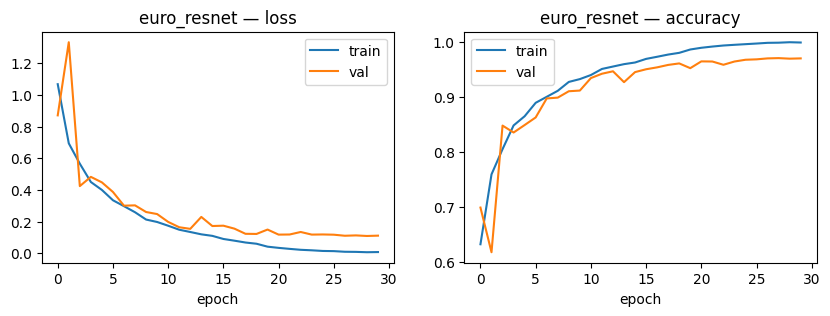

In [ ]:
train_model(euro_resnet, "euro_resnet", epochs=30, lr=1e-3)
plot_history("euro_resnet")

## Step 5: Transfer learning — fine-tuning a pretrained ResNet-18

The ImageNet-pretrained ResNet-18 is re-headed for 10 classes and fine-tuned end-to-end at **two
learning rates**: the pretrained backbone moves 10× slower than the fresh head, protecting features
that already encode edges and textures (which satellite imagery shares with natural images). The
64×64 inputs work as-is thanks to ResNet's adaptive average pooling — no upsampling to 224, so
training stays fast.

In [ ]:
torch.manual_seed(seed)
tl_model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
tl_model.fc = nn.Linear(tl_model.fc.in_features, 10)      # fresh 10-class head
tl_model = tl_model.to(device)
print("parameters:", sum(p.numel() for p in tl_model.parameters()))

head_params     = [p for n_, p in tl_model.named_parameters() if n_.startswith("fc.")]
backbone_params = [p for n_, p in tl_model.named_parameters() if not n_.startswith("fc.")]

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 175MB/s]


parameters: 11181642


[resnet18_finetune] epoch 01/15  train 0.9066  val 0.9314  (best 0.9314)
[resnet18_finetune] epoch 02/15  train 0.9566  val 0.9553  (best 0.9553)
[resnet18_finetune] epoch 03/15  train 0.9716  val 0.9531  (best 0.9553)
[resnet18_finetune] epoch 04/15  train 0.9752  val 0.9541  (best 0.9553)
[resnet18_finetune] epoch 05/15  train 0.9767  val 0.9620  (best 0.9620)
[resnet18_finetune] epoch 06/15  train 0.9863  val 0.9635  (best 0.9635)
[resnet18_finetune] epoch 07/15  train 0.9888  val 0.9526  (best 0.9635)
[resnet18_finetune] epoch 08/15  train 0.9916  val 0.9652  (best 0.9652)
[resnet18_finetune] epoch 09/15  train 0.9955  val 0.9679  (best 0.9679)
[resnet18_finetune] epoch 10/15  train 0.9968  val 0.9684  (best 0.9684)
[resnet18_finetune] epoch 11/15  train 0.9990  val 0.9711  (best 0.9711)
[resnet18_finetune] epoch 12/15  train 0.9991  val 0.9721  (best 0.9721)
[resnet18_finetune] epoch 13/15  train 0.9991  val 0.9751  (best 0.9751)
[resnet18_finetune] epoch 14/15  train 0.9994  val 

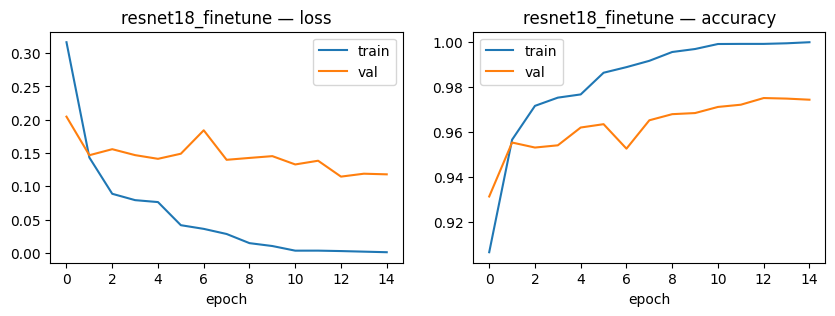

In [ ]:
param_groups = [
    {"params": backbone_params, "lr": 3e-4},   # pretrained features move slowly
    {"params": head_params,     "lr": 3e-3},   # new head learns fast
]
train_model(tl_model, "resnet18_finetune", epochs=15, lr=3e-3, param_groups=param_groups)
plot_history("resnet18_finetune")

## Step 6: Controlled experiments — augmentation and regularization

One variable at a time, always the same seed and the same routine, every result appended to
`RESULTS`: flip/rotate/crop/jitter augmentation, weight decay, and label smoothing — then the full
recipe combined on the pretrained ResNet-18. Augmentation is the satellite-specific one: patches
have no canonical "up", so flips and rotations multiply the training data at zero label cost.

### 1. Augmented training transforms

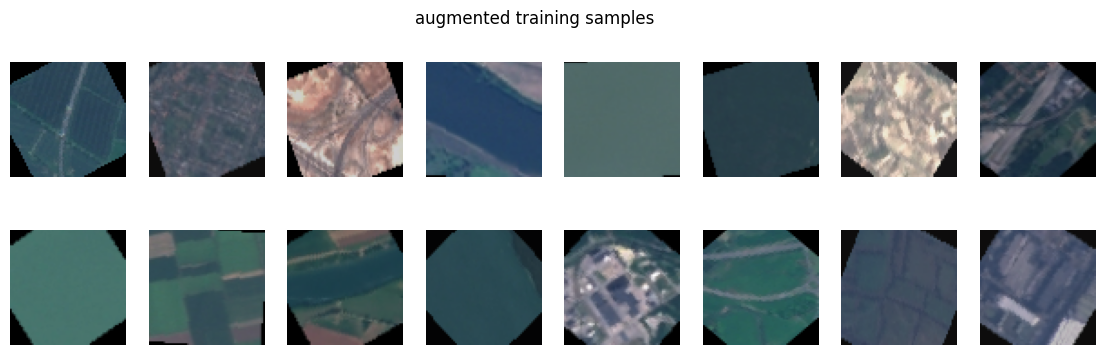

In [ ]:
aug_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(90),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomResizedCrop(64, scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# one augmented batch, de-normalized for display
aug_train, _, _ = make_loaders(aug_tf)
x, y = next(iter(aug_train))
inv = transforms.Normalize(-mean / std, 1 / std)
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(inv(x[i]).permute(1, 2, 0).clamp(0, 1)); ax.axis("off")
plt.suptitle("augmented training samples"); plt.show()

### 2. Ablations — one variable at a time

Each run below differs from Step 4 by exactly one knob (30 epochs, same seed); compare with
`euro_resnet` in the log at the end of this step.

In [ ]:
def run_experiment(name, model_fn, train_tf, **train_kw):
    """Fresh model + fresh loaders, same seed, same training routine."""
    torch.manual_seed(seed)
    model = model_fn().to(device)
    tr_ld, va_ld, _ = make_loaders(train_tf)
    train_model(model, name, train_ld=tr_ld, val_ld=va_ld, **train_kw)

run_experiment("resnet_aug",    EuroResNet, aug_tf, epochs=30, lr=1e-3)                        # + augmentation
run_experiment("resnet_aug_wd", EuroResNet, aug_tf, epochs=30, lr=1e-3, weight_decay=5e-4)     # + weight decay
run_experiment("resnet_aug_ls", EuroResNet, aug_tf, epochs=30, lr=1e-3, label_smoothing=0.1)   # + label smoothing

[resnet_aug] epoch 01/30  train 0.5385  val 0.6491  (best 0.6491)
[resnet_aug] epoch 02/30  train 0.6783  val 0.6509  (best 0.6509)
[resnet_aug] epoch 03/30  train 0.7340  val 0.7681  (best 0.7681)
[resnet_aug] epoch 04/30  train 0.7845  val 0.7632  (best 0.7681)
[resnet_aug] epoch 05/30  train 0.8198  val 0.8168  (best 0.8168)
[resnet_aug] epoch 06/30  train 0.8419  val 0.8481  (best 0.8481)
[resnet_aug] epoch 07/30  train 0.8651  val 0.8607  (best 0.8607)
[resnet_aug] epoch 08/30  train 0.8797  val 0.8459  (best 0.8607)
[resnet_aug] epoch 09/30  train 0.8954  val 0.8973  (best 0.8973)
[resnet_aug] epoch 10/30  train 0.9019  val 0.9291  (best 0.9291)
[resnet_aug] epoch 11/30  train 0.9140  val 0.8891  (best 0.9291)
[resnet_aug] epoch 12/30  train 0.9205  val 0.9227  (best 0.9291)
[resnet_aug] epoch 13/30  train 0.9240  val 0.9279  (best 0.9291)
[resnet_aug] epoch 14/30  train 0.9276  val 0.9136  (best 0.9291)
[resnet_aug] epoch 15/30  train 0.9347  val 0.9326  (best 0.9326)
[resnet_au

### 3. The full recipe on the pretrained ResNet-18

[resnet18_final] epoch 01/15  train 0.8540  val 0.9323  (best 0.9323)
[resnet18_final] epoch 02/15  train 0.9161  val 0.9333  (best 0.9333)
[resnet18_final] epoch 03/15  train 0.9303  val 0.9225  (best 0.9333)
[resnet18_final] epoch 04/15  train 0.9368  val 0.9516  (best 0.9516)
[resnet18_final] epoch 05/15  train 0.9417  val 0.9435  (best 0.9516)
[resnet18_final] epoch 06/15  train 0.9476  val 0.9491  (best 0.9516)
[resnet18_final] epoch 07/15  train 0.9514  val 0.9437  (best 0.9516)
[resnet18_final] epoch 08/15  train 0.9567  val 0.9563  (best 0.9563)
[resnet18_final] epoch 09/15  train 0.9593  val 0.9546  (best 0.9563)
[resnet18_final] epoch 10/15  train 0.9642  val 0.9622  (best 0.9622)
[resnet18_final] epoch 11/15  train 0.9672  val 0.9580  (best 0.9622)
[resnet18_final] epoch 12/15  train 0.9702  val 0.9583  (best 0.9622)
[resnet18_final] epoch 13/15  train 0.9735  val 0.9605  (best 0.9622)
[resnet18_final] epoch 14/15  train 0.9752  val 0.9595  (best 0.9622)
[resnet18_final] epo

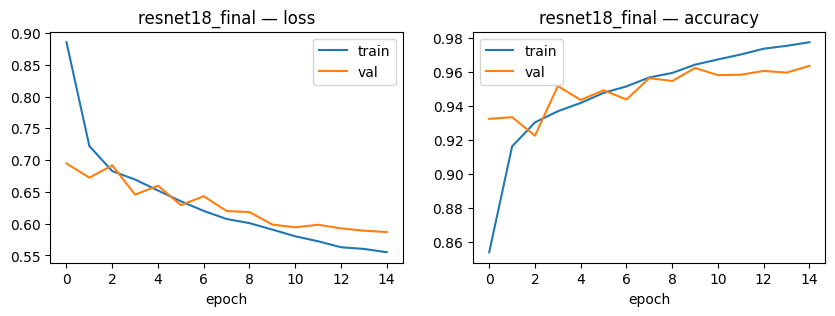

In [ ]:
torch.manual_seed(seed)
final_model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
final_model.fc = nn.Linear(final_model.fc.in_features, 10)
final_model = final_model.to(device)

head_params     = [p for n_, p in final_model.named_parameters() if n_.startswith("fc.")]
backbone_params = [p for n_, p in final_model.named_parameters() if not n_.startswith("fc.")]
aug_train_ld, aug_val_ld, _ = make_loaders(aug_tf)
param_groups = [{"params": backbone_params, "lr": 3e-4}, {"params": head_params, "lr": 3e-3}]

train_model(final_model, "resnet18_final", epochs=15, lr=3e-3, weight_decay=5e-4,
            label_smoothing=0.1, param_groups=param_groups,
            train_ld=aug_train_ld, val_ld=aug_val_ld)
plot_history("resnet18_final")

### 4. Experiment log

In [ ]:
import pandas as pd
rows = [{"experiment": k,
         "best_val_acc": f"{v['best_val_acc']:.4f}",
         "last_val_acc": f"{v['val_acc'][-1]:.4f}",
         "epochs": len(v["val_acc"])} for k, v in RESULTS.items()]
pd.DataFrame(rows).sort_values("best_val_acc", ascending=False)

,experiment,best_val_acc,last_val_acc,epochs
2,resnet18_finetune,0.9751,0.9743,15
1,euro_resnet,0.9701,0.9696,30
6,resnet18_final,0.9635,0.9635,15
4,resnet_aug_wd,0.9583,0.9553,30
5,resnet_aug_ls,0.9573,0.9570,30
3,resnet_aug,0.9565,0.9526,30
0,baseline_cnn,0.9259,0.9259,20


## Step 7: Final evaluation on the test set (used exactly once)

The winner by validation accuracy goes to the locked test split: overall accuracy, confusion
matrix, per-class accuracy, and a look at the images it still gets wrong.

In [ ]:
best_name = max(RESULTS, key=lambda k: RESULTS[k]["best_val_acc"])
final = MODELS[best_name]
print("winner:", best_name, f"| val acc {RESULTS[best_name]['best_val_acc']:.4f}")

test_loss, test_acc = evaluate(final, test_loader, nn.CrossEntropyLoss())
print(f"TEST accuracy ({best_name}): {test_acc:.4f}")

winner: resnet18_finetune | val acc 0.9751
TEST accuracy (resnet18_finetune): 0.9783


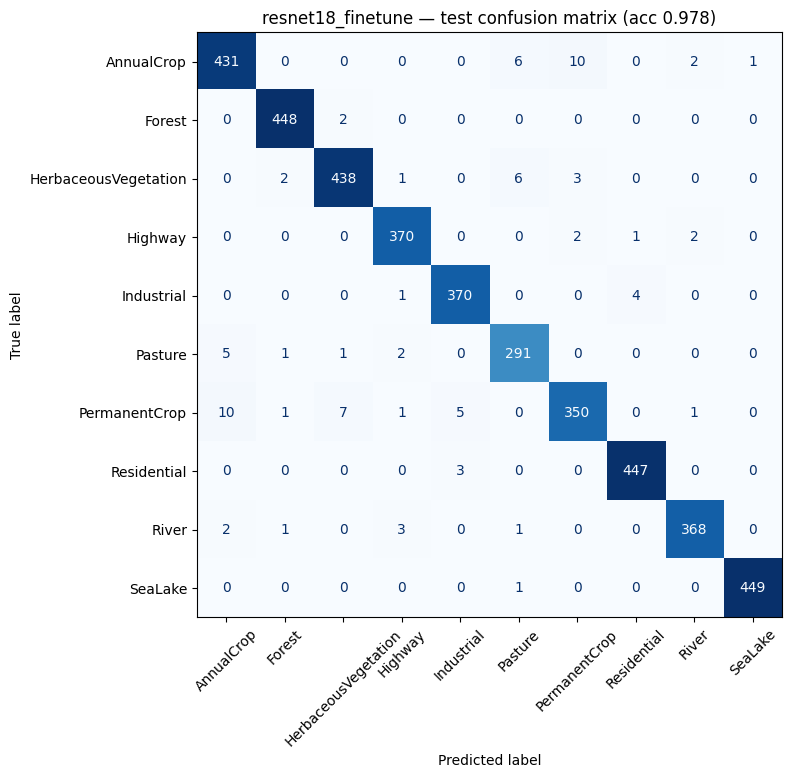

AnnualCrop             0.958
Forest                 0.996
HerbaceousVegetation   0.973
Highway                0.987
Industrial             0.987
Pasture                0.970
PermanentCrop          0.933
Residential            0.993
River                  0.981
SeaLake                0.998


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

@torch.no_grad()
def collect_preds(model, loader):
    model.eval(); ys, ps = [], []
    for x, y in loader:
        ps.append(model(x.to(device)).argmax(1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

y_true, y_pred = collect_preds(final, test_loader)
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues")
plt.title(f"{best_name} — test confusion matrix (acc {test_acc:.3f})")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

per_class = cm.diagonal() / cm.sum(1)
for c, a in zip(class_names, per_class): print(f"{c:22s} {a:.3f}")

test errors: 88 of 4050


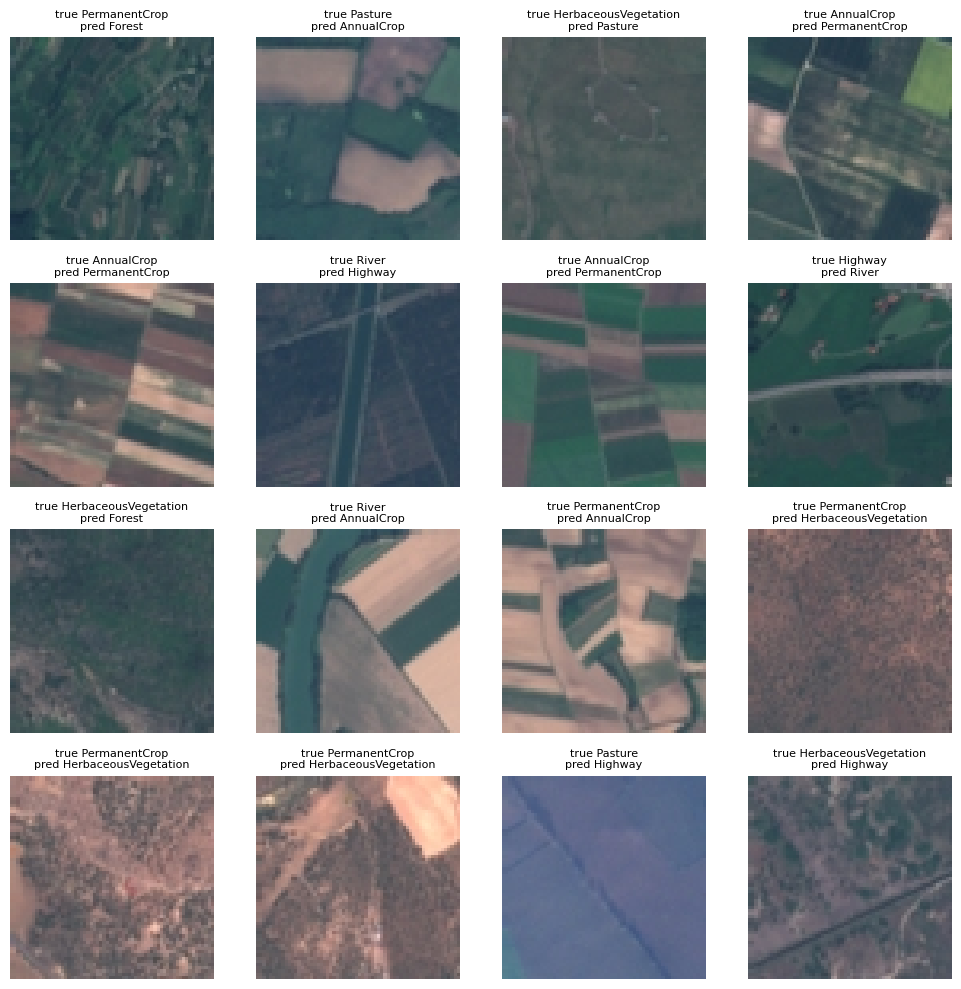

In [ ]:
# the surviving errors — true vs predicted label on raw (un-normalized) test images
wrong = np.where(y_pred != y_true)[0]
print("test errors:", len(wrong), "of", len(y_true))
rng = np.random.default_rng(seed)
show = rng.choice(wrong, size=min(16, len(wrong)), replace=False)
test_raw = Subset(raw, test_idx)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for ax, wi in zip(axes.flat, show):
    img, _ = test_raw[int(wi)]
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"true {class_names[y_true[wi]]}\npred {class_names[y_pred[wi]]}", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
torch.save(final.state_dict(), "best_model.pt")
print("saved best_model.pt")

saved best_model.pt


## 8 Discussion

**Results (best val acc):** baseline CNN 92.6% → ResNet-style CNN from scratch 97.0% → pretrained ResNet-18 fine-tuned 97.5% → + augmentation/weight decay/label smoothing 96.4%. The winner (fine-tuned ResNet-18) scored **97.8% on the test set**.

**What helped and why.** Architecture was the biggest gain (+4.4 pts): BatchNorm stabilized the deeper stack, residual shortcuts let eight conv layers train like shallow ones, and global average pooling replaced the 8,192-input FC head — the train−val gap shrank from ~7 to ~2.9 pts despite 5×
more parameters. Transfer learning added +0.5: ImageNet's low-level edge/texture filters transfer, though 18,900 training images already learn most of it from scratch.

**What did not help.** Augmentation scored lower (95.7% vs 97.0%) because 30 epochs is not enough for it to converge — train acc was still ~97% and val still climbing when training stopped; it needs 2–3× longer schedules. Weight decay and label smoothing changed nothing beyond noise: the same
baseline scored 92.6% and 93.1% across sessions, so differences under ~0.5 pts are not meaningful.

**Errors.** PermanentCrop (93.3%) and AnnualCrop (95.8%) are weakest — their distinguishing cue is the growth cycle, which a single 64×64 RGB patch cannot show — while Forest/SeaLake/Residential sit at 99.3–99.8%. The surviving ~2% looks like genuine ambiguity rather than under-fitting.